## Import Library

In [1]:
# 202431077_Siti Shafira Shafarina Amirullah

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report

print("Library Naive Bayes berhasil diimpor!")


Library Naive Bayes berhasil diimpor!


## Membaca Dataset Naive Bayes

In [2]:
# 202431077_Siti Shafira Shafarina Amirullah

df_nb = pd.read_csv("fetal_health.csv")

print("Dataset berhasil dibaca!")
print("Ukuran dataset:", df_nb.shape)

display(df_nb.head())

Dataset berhasil dibaca!
Ukuran dataset: (2126, 22)


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


## Melihat Informasi dan Statistik Dataset

In [3]:
# 202431077_Siti Shafira Shafarina Amirullah

print("Informasi Dataset:")
df_nb.info()

print("\nStatistik Deskriptif Dataset:")
display(df_nb.describe())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
count,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.00000,...,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000
mean,133.303857,0.003178,0.009481,0.004366,0.001889,0.000003,0.000159,46.990122,1.332785,9.84666,...,93.579492,164.025400,4.068203,0.323612,137.452023,134.610536,138.090310,18.808090,0.320320,1.304327
std,9.840844,0.003866,0.046666,0.002946,0.002960,0.000057,0.000590,17.192814,0.883241,18.39688,...,29.560212,17.944183,2.949386,0.706059,16.381289,15.593596,14.466589,28.977636,0.610829,0.614377
min,106.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,12.000000,0.200000,0.00000,...,50.000000,122.000000,0.000000,0.000000,60.000000,73.000000,77.000000,0.000000,-1.000000,1.000000
25%,126.000000,0.000000,0.000000,0.002000,0.000000,0.000000,0.000000,32.000000,0.700000,0.00000,...,67.000000,152.000000,2.000000,0.000000,129.000000,125.000000,129.000000,2.000000,0.000000,1.000000
50%,133.000000,0.002000,0.000000,0.004000,0.000000,0.000000,0.000000,49.000000,1.200000,0.00000,...,93.000000,162.000000,3.000000,0.000000,139.000000,136.000000,139.000000,7.000000,0.000000,1.000000
75%,140.000000,0.006000,0.003000,0.007000,0.003000,0.000000,0.000000,61.000000,1.700000,11.00000,...,120.000000,174.000000,6.000000,0.000000,148.000000,145.000000,148.000000,24.000000,1.000000,1.000000
max,160.000000,0.019000,0.481000,0.015000,0.015000,0.001000,0.005000,87.000000,7.000000,91.00000,...,159.000000,238.000000,18.000000,10.000000,187.000000,182.000000,186.000000,269.000000,1.000000,3.000000


## Memisahkan Fitur Numerik

In [4]:
# 202431077_Siti Shafira Shafarina Amirullah

fitur_numerik = df_nb.drop(columns=["fetal_health"]).select_dtypes(include=np.number).columns.tolist()

print("Jumlah fitur numerik:", len(fitur_numerik))
print("\nDaftar fitur numerik:")
print(fitur_numerik)

Jumlah fitur numerik: 21

Daftar fitur numerik:
['baseline value', 'accelerations', 'fetal_movement', 'uterine_contractions', 'light_decelerations', 'severe_decelerations', 'prolongued_decelerations', 'abnormal_short_term_variability', 'mean_value_of_short_term_variability', 'percentage_of_time_with_abnormal_long_term_variability', 'mean_value_of_long_term_variability', 'histogram_width', 'histogram_min', 'histogram_max', 'histogram_number_of_peaks', 'histogram_number_of_zeroes', 'histogram_mode', 'histogram_mean', 'histogram_median', 'histogram_variance', 'histogram_tendency']


## Identifikasi Fitur Kategorikal

In [5]:
# 202431077_Siti Shafira Shafarina Amirullah

fitur_kategorikal = df_nb.drop(columns=["fetal_health"]).select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Jumlah fitur kategorikal:", len(fitur_kategorikal))
print("\nDaftar fitur kategorikal:")
print(fitur_kategorikal)

Jumlah fitur kategorikal: 0

Daftar fitur kategorikal:
[]


## Menapilkan Nilai Unik Fitur Kategorikal

In [6]:
# 202431077_Siti Shafira Shafarina Amirullah

print("Nilai unik setiap fitur kategorikal:")

if len(fitur_kategorikal) > 0:
    for kolom in fitur_kategorikal:
        print(f"\n{kolom}:")
        print(df_nb[kolom].unique())
else:
    print("Tidak terdapat fitur kategorikal pada variabel input.")

Nilai unik setiap fitur kategorikal:
Tidak terdapat fitur kategorikal pada variabel input.


## Mengubah Fitur Kategorikal Menggunakan LabelEncoder

In [7]:
# 202431077_Siti Shafira Shafarina Amirullah

df_nb_encoded = df_nb.copy()

label_encoder = LabelEncoder()

for kolom in fitur_kategorikal:
    df_nb_encoded[kolom] = label_encoder.fit_transform(df_nb_encoded[kolom])

print("Proses Label Encoding berhasil!")
display(df_nb_encoded.head())

Proses Label Encoding berhasil!


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


## Memisahkan Data Fitur (X) dan Target (y)

In [8]:
# 202431077_Siti Shafira Shafarina Amirullah

X = df_nb_encoded.drop(columns=["fetal_health"])
y = df_nb_encoded["fetal_health"]

print("Jumlah fitur (X):", X.shape)
print("Jumlah target (y):", y.shape)

print("\nContoh data fitur:")
display(X.head())

print("\nContoh data target:")
display(y.head())

Jumlah fitur (X): (2126, 21)
Jumlah target (y): (2126,)

Contoh data fitur:


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_width,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0



Contoh data target:


0    2.0
1    1.0
2    1.0
3    1.0
4    1.0
Name: fetal_health, dtype: float64

## Membagi Data Training dan Testing

In [9]:
# 202431077_Siti Shafira Shafarina Amirullah

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=0
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

print("\nPembagian data berhasil!")

Jumlah data training: 1594
Jumlah data testing: 532

Pembagian data berhasil!


## Membuat dan Melatih Model Gaussian Naive Bayes

In [10]:
# 202431077_Siti Shafira Shafarina Amirullah

model_nb = GaussianNB()

model_nb.fit(X_train, y_train)

print("Model Gaussian Naive Bayes berhasil dilatih!")

Model Gaussian Naive Bayes berhasil dilatih!


## Melakukan Prediksi Data Training dan Testing

In [11]:
# 202431077_Siti Shafira Shafarina Amirullah

y_train_pred = model_nb.predict(X_train)
y_test_pred = model_nb.predict(X_test)

print("Prediksi data training berhasil dilakukan!")
print("Prediksi data testing berhasil dilakukan!")

print("\nContoh hasil prediksi training:")
print(y_train_pred[:10])

print("\nContoh hasil prediksi testing:")
print(y_test_pred[:10])

Prediksi data training berhasil dilakukan!
Prediksi data testing berhasil dilakukan!

Contoh hasil prediksi training:
[1. 2. 1. 2. 1. 1. 1. 1. 1. 1.]

Contoh hasil prediksi testing:
[1. 1. 2. 2. 2. 1. 1. 1. 1. 2.]


## Evaluasi Model pada Data Training

Confusion Matrix - Training:
[[1042  168   35]
 [  22  194    7]
 [   6   45   75]]

Classification Report - Training:
              precision    recall  f1-score   support

      Normal       0.97      0.84      0.90      1245
     Suspect       0.48      0.87      0.62       223
Pathological       0.64      0.60      0.62       126

    accuracy                           0.82      1594
   macro avg       0.70      0.77      0.71      1594
weighted avg       0.88      0.82      0.84      1594



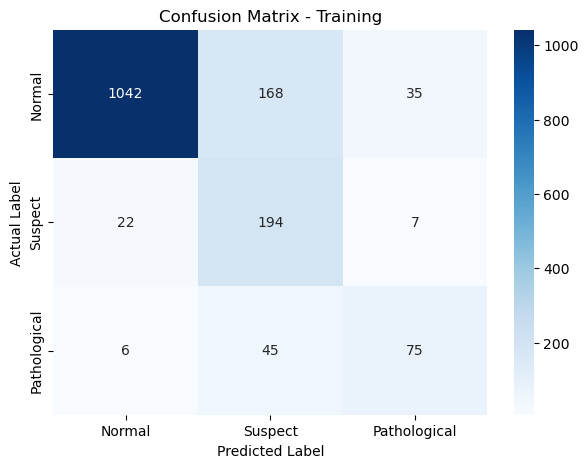

In [12]:
# 202431077_Siti Shafira Shafarina Amirullah

cm_train = confusion_matrix(y_train, y_train_pred)

print("Confusion Matrix - Training:")
print(cm_train)

print("\nClassification Report - Training:")
print(classification_report(
    y_train,
    y_train_pred,
    target_names=["Normal", "Suspect", "Pathological"]
))

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_train,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Suspect", "Pathological"],
    yticklabels=["Normal", "Suspect", "Pathological"]
)

plt.title("Confusion Matrix - Training")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

## Evaluasi Model pada Data Testing

Confusion Matrix - Testing:
[[330  61  19]
 [ 10  59   3]
 [  2  14  34]]

Classification Report - Testing:
              precision    recall  f1-score   support

      Normal       0.96      0.80      0.88       410
     Suspect       0.44      0.82      0.57        72
Pathological       0.61      0.68      0.64        50

    accuracy                           0.80       532
   macro avg       0.67      0.77      0.70       532
weighted avg       0.86      0.80      0.81       532



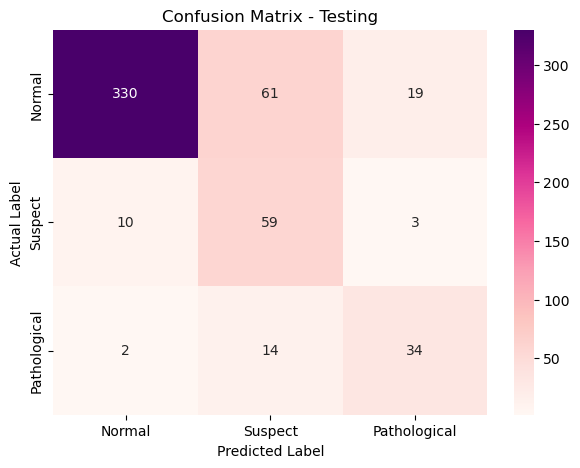

In [14]:
# 202431077_Siti Shafira Shafarina Amirullah

cm_test = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix - Testing:")
print(cm_test)

print("\nClassification Report - Testing:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Normal", "Suspect", "Pathological"]
))

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="RdPu",
    xticklabels=["Normal", "Suspect", "Pathological"],
    yticklabels=["Normal", "Suspect", "Pathological"]
)

plt.title("Confusion Matrix - Testing")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

## Prediksi Satu Data Baru 

In [15]:
# 202431077_Siti Shafira Shafarina Amirullah

data_baru = X_test.iloc[[0]]

prediksi_baru = model_nb.predict(data_baru)

nama_kategori = {
    1: "Normal",
    2: "Suspect",
    3: "Pathological"
}

print("Data baru:")
display(data_baru)

print("Hasil prediksi:", prediksi_baru[0])
print("Kategori kesehatan janin:", nama_kategori[int(prediksi_baru[0])])

Data baru:


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_width,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency
658,130.0,0.001,0.0,0.004,0.0,0.0,0.0,24.0,1.2,12.0,...,35.0,120.0,155.0,1.0,0.0,134.0,133.0,135.0,1.0,0.0


Hasil prediksi: 1.0
Kategori kesehatan janin: Normal
